# code_163 · Active inspection with explicit query costs

**Book:** section 31.3. A self-contained limited-label learning laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Imports, helpers and inputs are internal; ordinary execution needs no files, network, credentials, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_31_GUIDE.md), [run evidence](../CHAPTER_31_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_163).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Splits, fitted transformations, model selection and assessment declare their evidence boundaries locally. Synthetic cohort sizes and prevalences are constructed rather than population estimates. All numerical data are generated. These comparisons expose structural assumptions, information boundaries and transformation contracts without field-validity, causal or universal physical-model claims.


In [1]:
import platform,time,json,copy,hashlib
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
import threadpoolctl
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=4263;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
import torch
from torch import nn
torch.set_num_threads(1);torch.set_default_dtype(torch.float64);torch.manual_seed(SEED);torch.use_deterministic_algorithms(True)
VERSIONS['torch']=torch.__version__
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0'}
CPU: Darwin arm64 seed: 4263


<a id="sequential-costed-acquisition"></a>
 ## Acquire observed labels without acquiring a biased test set
 Four independent generated cohorts each contain 240 candidate buildings and 120 separate final buildings, one record per building. The first six candidate labels are observed initially at cost one each. Later query costs are one or three units, fixed from known access conditions. Compare uniform affordable random sampling, entropy per cost, farthest-from-labelled diversity per cost and tree-committee disagreement per cost. The classifier is a fixed 20-tree random forest, depth 5/minimum leaf 2, rebuilt after each query. Checkpoints at total costs 6/16/26/36/46 include the initial labels. All policies share each cohort and initial records. Candidate feature scaling for distance uses the available unlabelled pool only; final measurements never fit it. Independent final labels are used only to report each completed checkpoint.


,policy,budget,mean_final_accuracy,cohort_SD_accuracy,mean_observed_building_labels,mean_spent
0,Random,6,0.560417,0.023936,6.0,6.0
1,Random,16,0.625000,0.076679,13.0,16.0
2,Random,26,0.620833,0.082074,18.0,26.0
3,Random,36,0.677083,0.092390,24.5,36.0
4,Random,46,0.733333,0.084437,31.5,46.0
5,Uncertainty,6,0.560417,0.023936,6.0,6.0
6,Uncertainty,16,0.706250,0.027534,16.0,16.0
7,Uncertainty,26,0.745833,0.022048,26.0,26.0
8,Uncertainty,36,0.772917,0.047324,36.0,36.0
9,Uncertainty,46,0.783333,0.058926,46.0,46.0


,repeat,policy,queried_positive_fraction,independent_final_positive_fraction,queried_resubstitution_accuracy
0,0,Random,0.607143,0.516667,1.000000
1,0,Uncertainty,0.478261,0.516667,0.978261
2,0,Diversity,0.500000,0.516667,0.934783
3,0,Committee,0.478261,0.516667,0.956522
4,1,Random,0.437500,0.433333,0.968750
5,1,Uncertainty,0.521739,0.433333,0.978261
6,1,Diversity,0.565217,0.433333,1.000000
7,1,Committee,0.500000,0.433333,0.934783
8,2,Random,0.593750,0.525000,1.000000
9,2,Uncertainty,0.521739,0.525000,0.978261


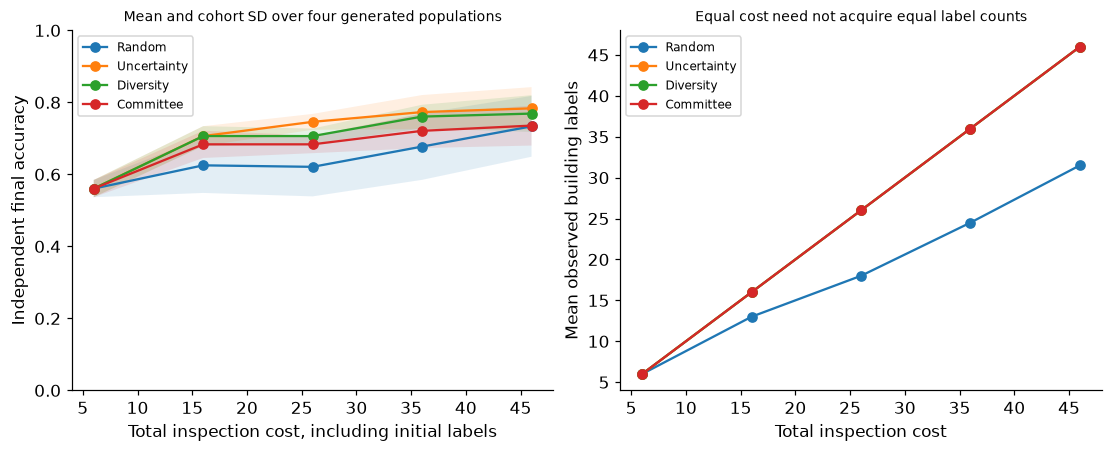

In [2]:
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
budgets=[6,16,26,36,46];policies=['Random','Uncertainty','Diversity','Committee'];rows=[];logs={};final_snapshots={}
def cohort(n,generator):
    x=generator.uniform(-1,1,(n,3));latent=1.2*x[:,0]*x[:,1]+.4*x[:,2]+.15*np.sin(4*x[:,0]);y=(latent+generator.normal(0,.07,n)>0).astype(int);return x,y
def binary_prob(model,x):
    p=model.predict_proba(x);out=np.zeros((len(x),2));out[:,model.classes_.astype(int)]=p;return out
for repeat in range(4):
    gr=np.random.default_rng(SEED+repeat);pool_x,pool_y=cohort(240,gr);final_x,final_y=cohort(120,gr);cost=np.where(pool_x[:,1]>.25,3,1);cost[:6]=1;scaled=StandardScaler().fit_transform(pool_x);pool_ids=np.arange(240);final_ids=np.arange(1000,1120);assert not set(pool_ids)&set(final_ids)
    for policy_index,policy in enumerate(policies):
        chosen=list(range(6));observed=pool_y[:6].tolist();spent=6;query_log=[];qr=np.random.default_rng(SEED+100*repeat+policy_index)
        def fit_model():return RandomForestClassifier(n_estimators=20,max_depth=5,min_samples_leaf=2,random_state=SEED,n_jobs=1).fit(pool_x[chosen],observed)
        model=fit_model()
        for budget in budgets:
            while True:
                available=np.array([i for i in pool_ids if i not in chosen and spent+cost[i]<=budget],dtype=int)
                if not len(available):break
                if policy=='Random':query=int(qr.choice(available))
                else:
                    pp=binary_prob(model,pool_x[available])
                    if policy=='Uncertainty':utility=-np.sum(pp*np.log(np.clip(pp,1e-12,1)),1)
                    elif policy=='Diversity':utility=np.sqrt(np.min(np.sum((scaled[available,None,:]-scaled[np.array(chosen)][None,:,:])**2,axis=2),axis=1))
                    else:
                        member=[]
                        for tree in model.estimators_:
                            # Forest estimators share encoded global class positions.
                            tp=tree.predict_proba(pool_x[available]);member.append(tp[:,-1] if tp.shape[1]==2 else np.zeros(len(available)))
                        utility=np.var(member,axis=0)
                    query=int(available[np.argmax(utility/cost[available])])
                # Only this selected candidate outcome is admitted by the oracle.
                label=int(pool_y[query]);chosen.append(query);observed.append(label);spent+=int(cost[query]);query_log.append({'building':query,'label':label,'cost':int(cost[query]),'cumulative_cost':spent});model=fit_model()
            p=binary_prob(model,final_x);prediction=p.argmax(1);rows.append({'repeat':repeat,'policy':policy,'budget':budget,'spent':spent,'observed_building_labels':len(chosen),'final_accuracy':float(np.mean(prediction==final_y)),'final_Brier':float(np.mean(np.sum((p-np.eye(2)[final_y])**2,1)))})
        assert len(chosen)==len(set(chosen)) and spent<=46 and sum(q['cost'] for q in query_log)+6==spent and len(observed)==len(chosen)
        logs[(repeat,policy)]=query_log;final_snapshots[(repeat,policy)]={'queried_positive_fraction':float(np.mean(observed)),'independent_final_positive_fraction':float(np.mean(final_y)),'queried_resubstitution_accuracy':float(np.mean(model.predict(pool_x[chosen])==observed))}
summary=[]
for policy in policies:
    for budget in budgets:
        rr=[r for r in rows if r['policy']==policy and r['budget']==budget];summary.append({'policy':policy,'budget':budget,'mean_final_accuracy':float(np.mean([r['final_accuracy'] for r in rr])),'cohort_SD_accuracy':float(np.std([r['final_accuracy'] for r in rr],ddof=1)),'mean_observed_building_labels':float(np.mean([r['observed_building_labels'] for r in rr])),'mean_spent':float(np.mean([r['spent'] for r in rr]))})
RESULTS.update(candidate_buildings_per_repeat=240,independent_final_buildings_per_repeat=120,cohort_repeats=4,total_cost_checkpoints=budgets,initial_observed_labels=6,query_costs=[1,3],forest_trees=20,forest_depth=5,metrics=summary,individual_checkpoint_results=rows,final_query_sample_diagnostics=[dict(repeat=k[0],policy=k[1],**v) for k,v in final_snapshots.items()],first_query_log=logs[(0,'Uncertainty')][:5],final_outcomes_admitted_to_acquisition=0);display(pd.DataFrame(summary));display(pd.DataFrame(RESULTS['final_query_sample_diagnostics']))
fig,axes=plt.subplots(1,2,figsize=(10,4))
for policy in policies:
    rr=[r for r in summary if r['policy']==policy];x=[r['budget'] for r in rr];y=np.array([r['mean_final_accuracy'] for r in rr]);sd=np.array([r['cohort_SD_accuracy'] for r in rr]);axes[0].plot(x,y,marker='o',label=policy);axes[0].fill_between(x,y-sd,y+sd,alpha=.12);axes[1].plot(x,[r['mean_observed_building_labels'] for r in rr],marker='o',label=policy)
axes[0].set(xlabel='Total inspection cost, including initial labels',ylabel='Independent final accuracy',ylim=(0,1),title='Mean and cohort SD over four generated populations');axes[0].legend(fontsize=8);axes[1].set(xlabel='Total inspection cost',ylabel='Mean observed building labels',title='Equal cost need not acquire equal label counts');axes[1].legend(fontsize=8);plt.show()


<a id="acquisition-is-not-evaluation"></a>
 ## The queried sample changes with the policy
 Query logs preserve which whole building was selected, when its outcome became visible and the cost charged. An uncertain or diverse sample is deliberately unrepresentative of uniform sampling; its observed label fraction and training resubstitution score do not estimate deployment error. Only the independent final population supports the plotted assessment. The shaded cohort SD describes variation over four generated cohorts, not a confidence interval or a guarantee that active sampling helps. All classifiers, query policies and checkpoints are fixed; there is no separate development search in this laboratory. Committee variance can be small even when all members share the same bias, and diversity depends on the chosen feature scale.


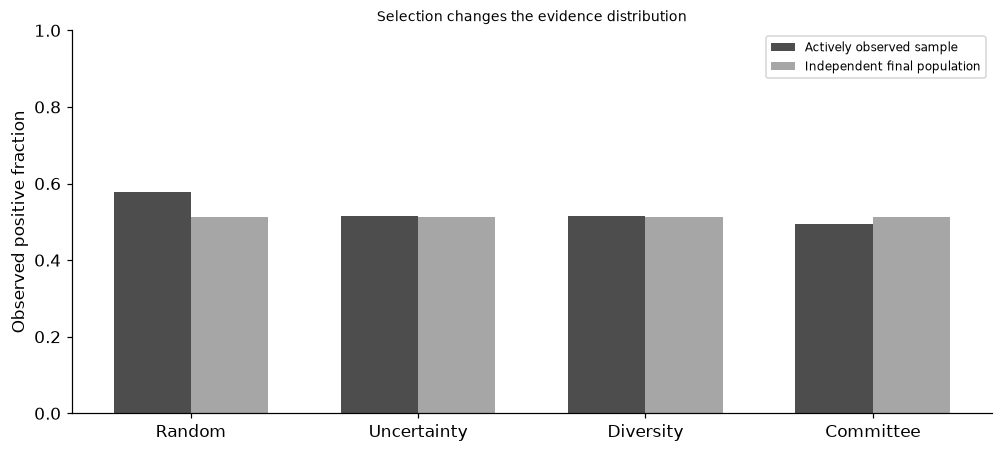

In [3]:
fig,ax=plt.subplots(figsize=(9,4));xx=np.arange(4);queried=[np.mean([v['queried_positive_fraction'] for k,v in final_snapshots.items() if k[1]==policy]) for policy in policies];reference=[np.mean([v['independent_final_positive_fraction'] for k,v in final_snapshots.items() if k[1]==policy]) for policy in policies];ax.bar(xx-.17,queried,width=.34,color='.3',label='Actively observed sample');ax.bar(xx+.17,reference,width=.34,color='.65',label='Independent final population');ax.set(xticks=xx,xticklabels=policies,ylim=(0,1),ylabel='Observed positive fraction',title='Selection changes the evidence distribution');ax.legend(fontsize=8);plt.show()
assert len(rows)==80 and len(summary)==20 and all(r['spent']<=r['budget'] for r in rows)


In [4]:
summary={'example_id':'code_163','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['actual sequential random uncertainty diversity and committee acquisition', 'whole-building oracle admission and explicit cost budget', 'same initial labels and independent final population across policies', 'four generated cohort seeds and descriptive policy variability', 'query sample separated from deployment evaluation'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
if 'resource_profile' in globals():summary['resource_observations']=resource_profile
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["actual sequential random uncertainty diversity and committee acquisition", "whole-building oracle admission and explicit cost budget", "same initial labels and independent final population across policies", "four generated cohort seeds and descriptive policy variability", "query sample separated from deployment evaluation"], "elapsed_seconds": 5.943, "example_id": "code_163", "hardware": "Darwin arm64 CPU", "results": {"candidate_buildings_per_repeat": 240, "cohort_repeats": 4, "final_outcomes_admitted_to_acquisition": 0, "final_query_sample_diagnostics": [{"independent_final_positive_fraction": 0.5166666666666667, "policy": "Random", "queried_positive_fraction": 0.6071428571428571, "queried_resubstitution_accuracy": 1.0, "repeat": 0}, {"independent_final_positive_fraction": 0.5166666666666667, "policy": "Uncertainty", "queried_positive_fraction": 0.4782608695652174, "queried_resubstitution_accuracy": 0.9782608695652174, "repeat": 0}, 